## Systematics uncertainty estimates from Jackkniffe tests (data perturbations) 

### Systematic across Observations

**Goal:** Probe the stability of the fit with respect to observation-to-observation differences, including potential unknown systematic effects.


## Imports

In [1]:
from gammapy.datasets import Datasets
from gammapy.modeling import Fit
from gammapy.modeling.models import FoVBackgroundModel, PowerLawNormSpectralModel, TemplateSpatialModel, SkyModel, Models
from gammapy.catalog import CATALOG_REGISTRY

import numpy as np
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt
import astropy.units as u
import gc
from gammapy.stats import ts_to_sigma
import itertools

/Users/qremy/anaconda3/envs/gpy-dev12/lib/python3.12/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


## Load datasets

From previous notebook 2a_hess_data_reduction.ipynb


In [2]:
datasets = Datasets.read(
    filename="./datasets/hess_rxj_datasets.yaml",
    filename_models="./models/hess_rxj_models.yaml",
)


In [3]:
model_iem = datasets.models["IEM_varmin_rescaled"]

In [4]:
bkgs = [FoVBackgroundModel(dataset_name=d.name,
                                  spectral_model=PowerLawNormSpectralModel()
                                 ) for d in datasets]

In [5]:
geom = datasets[0].counts.geom

In [6]:
catalog_hgps = CATALOG_REGISTRY.get_cls("hgps")()  # load HGPS catalog
in_geom = geom.to_image().contains(catalog_hgps.positions)
catalog_hgps_geom = catalog_hgps[in_geom]
models_hgps_geom = catalog_hgps_geom.to_models()


In [7]:
models_hgps_geom.freeze()
for m in models_hgps_geom:
    m.spatial_model.lon_0.min = geom.footprint.galactic.l.value.min()
    m.spatial_model.lon_0.max = geom.footprint.galactic.l.value.max()
    m.spatial_model.lat_0.min = geom.footprint.galactic.b.value.min()
    m.spatial_model.lat_0.max = geom.footprint.galactic.b.value.max()
    if m.spatial_model.tag[0] == "ShellSpatialModel":
        model_name = m.name
        m.unfreeze("spectral")
        model_ref = m

models = models_hgps_geom+ bkgs + [model_iem]

In [8]:
#just speed-up this tutorial
datasets = Datasets([d.downsample(factor=5).cutout(d.counts.geom.center_skydir, width=5*u.deg) for d in datasets])

HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found


In [9]:
datasets.models = models.copy()

In [10]:
len(datasets)

12

## Stacked dataset

Stacking is usually performed to reduce computation time. However, it should be kept in mind that it introduces a loss of information in the IRF modelling, as observation-specific IRFs are averaged, thereby introducing systematic uncertainties.

In [11]:
stacked = datasets.copy().stack_reduce()

(<WCSAxes: >,
 <Axes: xlabel='Energy [$\\mathrm{TeV}$]', ylabel='Residuals (data - model)'>)

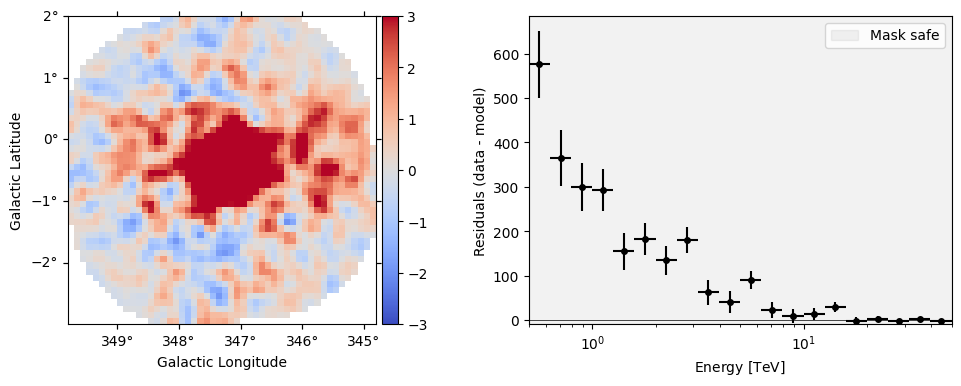

In [12]:
stacked.plot_residuals(kwargs_spatial=dict(vmin=-3, vmax=3))

In [13]:
bkg_stacked =  FoVBackgroundModel(dataset_name=stacked.name,
                                  spectral_model=PowerLawNormSpectralModel()
                                 )

stacked.models =  models.copy() + [bkg_stacked]

## Joint versus stacked

How different are the fit results between the stacked analysis and the joint analysis ?

In [14]:
fit = Fit()

In [15]:
%%time
results_joint = fit.run(datasets)

Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Model HESS J1702-420 is outside the target geom but contributes inside through the psf.This contribution cannot be estimated precisely.Consider extending the dataset geom and/or the masked margin in the mask_fit.
Model HESS J1718-374 is outside the target geom but contributes inside through the psf.This contribution cannot be estimated precisely.Consider extending the dataset geom and/or the masked margin in the mask_fit.
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Po

CPU times: user 33.3 s, sys: 381 ms, total: 33.7 s
Wall time: 33.9 s


In [16]:
%%time
results_stacked = fit.run(stacked)
results_stacked

Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within


CPU times: user 2.69 s, sys: 20.1 ms, total: 2.71 s
Wall time: 2.72 s


(<WCSAxes: >,
 <Axes: xlabel='Energy [$\\mathrm{TeV}$]', ylabel='Residuals (data - model)'>)

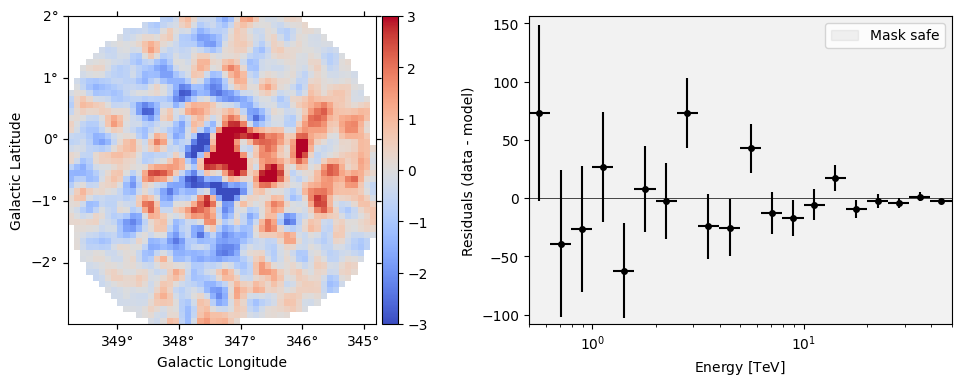

In [17]:
stacked.plot_residuals(kwargs_spatial=dict(vmin=-3, vmax=3))

In [18]:
results_stacked.models[bkg_stacked.name].spectral_model.parameters.to_table()

type,name,value,unit,error,min,max,frozen,link,prior
str1,str9,float64,str3,float64,float64,float64,bool,str1,str1
,tilt,0.0000e+00,,0.000e+00,nan,nan,True,,
,norm,1.0258e+00,,7.653e-03,nan,nan,False,,
,reference,1.0000e+00,TeV,0.000e+00,nan,nan,True,,


In [19]:
results_stacked.models[model_name].parameters.to_table()

type,name,value,unit,error,min,max,frozen,link,prior
str1,str9,float64,str14,float64,float64,float64,bool,str1,str1
,index,2.0650e+00,,9.500e-02,nan,nan,False,,
,amplitude,2.0182e-11,TeV-1 s-1 cm-2,1.155e-12,nan,nan,False,,
,reference,1.0000e+00,TeV,0.000e+00,nan,nan,True,,
,lambda_,4.6307e-02,TeV-1,2.370e-02,nan,nan,False,,
,alpha,1.0000e+00,,0.000e+00,nan,nan,True,,
,lon_0,3.4731e+02,deg,0.000e+00,3.433e+02,3.513e+02,True,,
,lat_0,-4.5735e-01,deg,0.000e+00,-4.489e+00,3.491e+00,True,,
,radius,4.7500e-01,deg,0.000e+00,nan,nan,True,,
,width,2.5000e-02,deg,0.000e+00,nan,nan,True,,


/Users/qremy/Work/GitHub/gammapy/gammapy/modeling/models/spectral.py:650: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.plot(energy.center, flux.quantity[:, 0, 0], **kwargs)


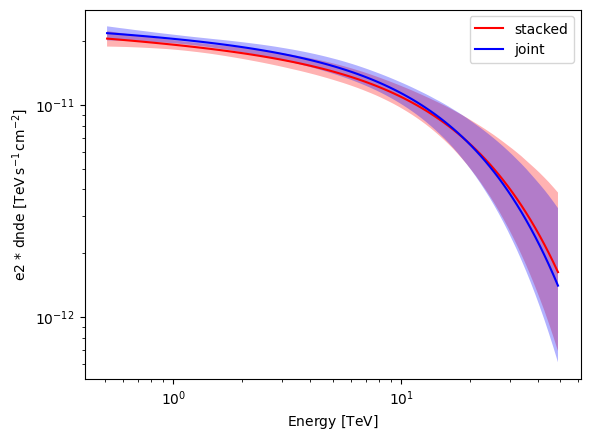

In [20]:
plt.figure()
spec_kwargs = dict(
        energy_bounds=[0.5, 50]*u.TeV,
        energy_power=2
        )

results_stacked.models[model_name].spectral_model.plot(color="r", label="stacked", **spec_kwargs)
results_stacked.models[model_name].spectral_model.plot_error(facecolor="r", alpha=0.3, **spec_kwargs)
results_joint.models[model_name].spectral_model.plot(color="b", label="joint", **spec_kwargs)
results_joint.models[model_name].spectral_model.plot_error(facecolor="b", alpha=0.3, **spec_kwargs)
plt.legend()

In [21]:
stat = stacked.stat_sum()
with stacked.models.parameters.restore_status():
    stacked.models[model_name].spectral_model.amplitude.value=0
    stat_null = stacked.stat_sum()
    ts_stacked = stat_null-stat
    
print("Detection TS", ts_stacked)
dof = len(stacked.models[model_name].parameters.free_parameters)
print("Degree of freedom", dof)
sigma_stacked = ts_to_sigma(ts_stacked, dof )
print("Detection significance",sigma_stacked)

Detection TS 720.7167467238942
Degree of freedom 3
Detection significance 26.600170663704045


In [22]:
stat = datasets.stat_sum()
with datasets.models.parameters.restore_status():
    datasets.models[model_name].spectral_model.amplitude.value=0
    stat_null = datasets.stat_sum()
    ts_joint = stat_null-stat
    
print("Detection TS", ts_joint)
dof = len(stacked.models[model_name].parameters.free_parameters)
print("Degree of freedom", dof)
sigma_joint = ts_to_sigma(ts_joint, dof )
print("Detection significance",sigma_joint)

Detection TS 849.9628940234543
Degree of freedom 3
Detection significance 28.92202899969283


## What can we learn from refitting subsets of the dataset?

- Does a subset of the data drive or bias the fit?

- What systematic effects are related to the stacking procedure? Are there outliers that bias the averaged IRFs?

- What are the biases and uncertainties on the fitted parameters?

- What are the uncertainties on a given test statistic?


In [23]:
#First let's define a function to do the fitting and then we will see how to define the subsamples
def fit_subsamples(datasets, subsamples_idx, use_case="stacked", model_name=None):
    results_samples = []
    ts_samples = []
    n_samples = len(subsamples_idx)
    for k in range(n_samples):
        print(k+1, f"/{n_samples}")
    
        models_k = models.copy()
        datasets.models = models_k #reset to default model
        datasets_n_minus_k =Datasets([d for kd, d in enumerate(datasets) if kd not in subsamples_idx[k]])
        datasets_k =  [d for kd, d in enumerate(datasets) if kd in subsamples_idx[k]]
    
        stacked_n_minus_k = datasets_n_minus_k.stack_reduce(name=f"stacked_n_minus_k")
        bkg_stacked =  FoVBackgroundModel(dataset_name=stacked_n_minus_k.name,
                                      spectral_model=PowerLawNormSpectralModel()
                                     )
    
        stacked_n_minus_k.models = models_k + [bkg_stacked]

        if use_case == "joint":
            # does a subset of the data drives the fit ?
            test_datasets = datasets_n_minus_k
    
        if use_case == "stacked":
            # does a subset of the data drives the fit / or includes outliers biasing irfs average?
            test_datasets = stacked_n_minus_k
    
        if use_case == "k-joint":  # k-joint and the others stacked
            # what's the error introduce by stacking ?
            # this test perform staking by pieces if all joint is too memory heavy,
            # dependend on n_obs find a good k as a trade-off between computation time and memory usage 
            test_datasets = Datasets(datasets_k+[stacked_n_minus_k])

        results_k = fit.run(test_datasets)

        results_samples.append(results_k.models)

        if model_name:
            stat = test_datasets.stat_sum()
            with test_datasets.models.parameters.restore_status():
                test_datasets.models[model_name].spectral_model.amplitude.value=0
                stat_null = test_datasets.stat_sum()
                ts_samples.append(stat_null-stat)
    
        del test_datasets, datasets_n_minus_k, datasets_k, stacked_n_minus_k #force to free memory to avoid leak
        # especially important in notebook as they deal with memory differently
        gc.collect()
    return results_samples, ts_samples

## Resampling strategies

### Leave-one-out 


For N observation we are going to refit the model the model N times with N-1 observations, removing each once observation at a time.
The jackknife uses a leave-one-out resampling procedure similar to leave-one-out cross-validation (LOOCV). However, the objective differs: LOOCV is typically used to evaluate the predictive performance of a model on unseen data, whereas the jackknife is primarily used to estimate biases and uncertainties on model parameters.


In [24]:
n_obs = len(datasets)
subsamples_idx = [[idx] for idx in range(n_obs)]

In [25]:
subsamples_idx

[[0], [1], [2], [3], [4], [5], [6], [7], [8], [9], [10], [11]]

In [26]:
results_samples, ts_samples = fit_subsamples(datasets, subsamples_idx, use_case="stacked", model_name=model_name)


1 /12


Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within


2 /12


Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within


3 /12


...

Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within


11 /12


Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within


12 /12


Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within


Let's look at the distribution of TS 

Text(0.5, 0, 'Detection significance')

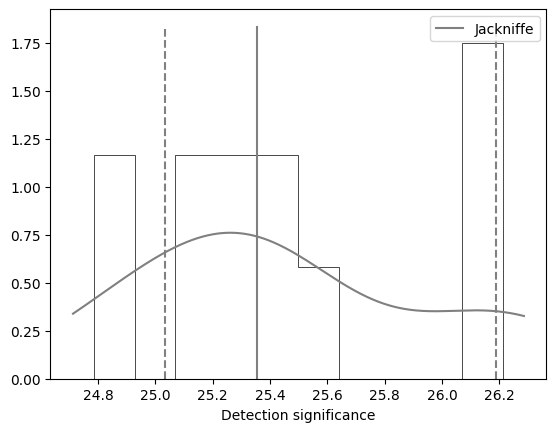

In [27]:
plt.figure()
sigma_samples = ts_to_sigma(ts_samples, dof)
plt.hist(sigma_samples, bins=10, color="k", lw=0.5, histtype="step", density=True)
xl=plt.xlim()
yl = plt.ylim()
x = np.linspace(xl[0], xl[1], 1000)
plt.plot(x, gaussian_kde(sigma_samples).pdf(x), color="gray")
plt.plot([np.percentile(sigma_samples, 50)]*2, yl , color="gray", ls="-", label="Jackniffe")
plt.plot([np.percentile(sigma_samples, 16)]*2, yl , color="gray", ls="--")
plt.plot([np.percentile(sigma_samples, 84)]*2, yl , color="gray", ls="--")
plt.legend()
plt.xlabel("Detection significance")


In this example, we do not have enough samples to derive robust estimates of the mean and uncertainty, but we can employ an alternative sampling strategy.

## Leave-k-out

Similar to the leave-one-out approach, but k observations are removed at each iteration, and the procedure is repeated over all possible combinations.

In [28]:


n_obs = len(datasets)
ids = np.arange(n_obs)
k=3
n_max = 10000 # in principle it should be exhaustive doing every possible combinaisons, just added that for testing 
permutations = np.random.permutation([x for x in itertools.permutations(ids,k)])
subsamples_idx = permutations[:np.minimum(n_max, len(permutations))]
n_samples = len(subsamples_idx)
print(n_samples)

1320


In [29]:
%%time
results_samples, ts_samples = fit_subsamples(datasets, subsamples_idx, use_case="stacked", model_name=model_name)
#"k-joint" don't remove the sub-sample but fit it jointly while the others are stacked

1 /1320


Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within


2 /1320


Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within


3 /1320


...

1319 /1320


Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within


1320 /1320


Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within


CPU times: user 1h 18min 2s, sys: 1min 42s, total: 1h 19min 44s
Wall time: 1h 20min 49s


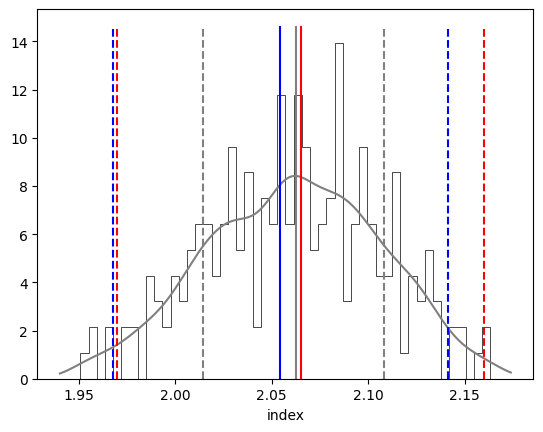

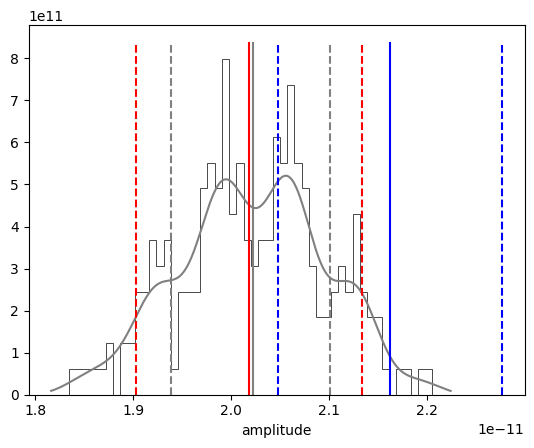

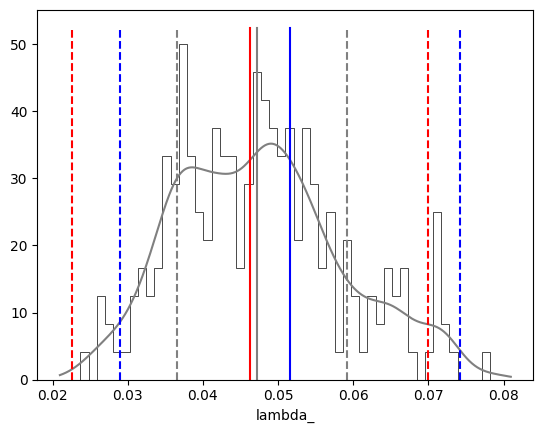

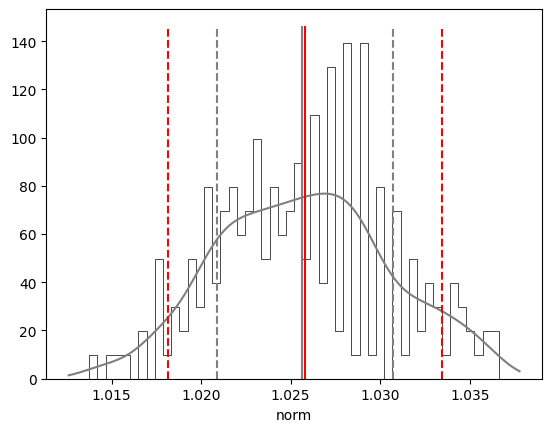

In [30]:
params_samples = []

selected_models =  Models([model_ref, bkg_stacked])
for par_name in selected_models.parameters.free_parameters.names:
    par_samples = []
    for k in range(n_samples):
        par_samples.append(results_samples[k].parameters.free_parameters[par_name].value)
    plt.figure()
    plt.hist(par_samples, bins=50, color="k", lw=0.5, histtype="step", density=True)
    xl=plt.xlim()
    yl = plt.ylim()
    x = np.linspace(xl[0], xl[1], 1000)
    plt.plot(x, gaussian_kde(par_samples).pdf(x), color="gray")
    plt.plot([np.percentile(par_samples, 50)]*2, yl , color="gray", ls="-", label="systematic (jackknife)")
    plt.plot([np.percentile(par_samples, 16)]*2, yl , color="gray", ls="--")
    plt.plot([np.percentile(par_samples, 84)]*2, yl , color="gray", ls="--")
    value = results_stacked.parameters.free_parameters[par_name].value
    error = results_stacked.parameters.free_parameters[par_name].error
    plt.plot([value]*2, yl , color="r", label="stacked")
    plt.plot([value-error]*2, yl , color="r", ls="--")
    plt.plot([value+error]*2, yl , color="r", ls="--")
    plt.xlabel(par_name)

    if par_name != "norm":
        value = results_joint.parameters.free_parameters[par_name].value
        error = results_joint.parameters.free_parameters[par_name].error
        plt.plot([value]*2, yl , color="b", label="joint")
        plt.plot([value-error]*2, yl , color="b", ls="--")
        plt.plot([value+error]*2, yl , color="b", ls="--")

    params_samples.append(par_samples)

params_samples = np.array(params_samples).T

The amplitude distribution exhibits an unusual pattern. This may be because the observations are position-dependent and, depending on which observation is removed, the sensitivity across the shell varies. As a result, different substructures with different flux levels may drive the fit. To investigate this effect, we could perform an additional test by applying the mask at random pixel positions within the shell (see the next notebook). Alternatively, it could be due to observation-to-observation systematic effects in the effective area.

In [31]:
import xarray as xr

def sample_parameters_from_covariance(models, samples=None, n_samples=1000):
    if samples is None:
        samples = models.sample_parameters_from_covariance(n_samples=n_samples)

    posterior = xr.Dataset(
        {
            par_name: (("draw", "chain"), samples[:, kp][None,:])
            for kp, par_name in enumerate(
                models.parameters.free_parameters.names
            )
        }
    )

    return xr.DataTree.from_dict({"posterior": posterior})

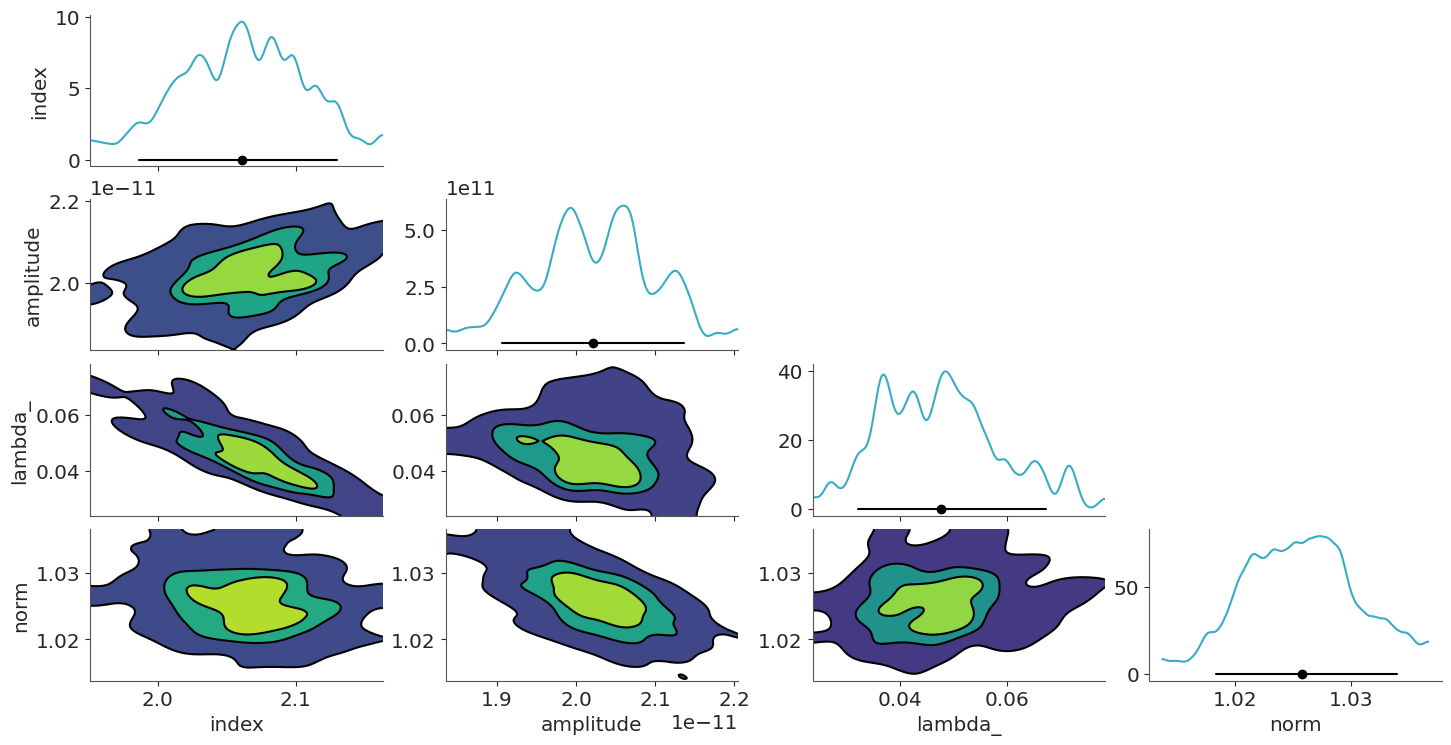

In [32]:
import arviz as az

az.style.use("arviz-variat")

data = sample_parameters_from_covariance(selected_models, samples=params_samples)

az.plot_pair(
    data,
    marginal=True,
    marginal_kind="kde",
    visuals={
             "credible_interval":{"color":"k"},"point_estimate":{"color":"k"},
             "contourf": True,
             "contour": {"color":"black"},
             "scatter":False,
    }
)
plt.show()

In [33]:
### comparison to covariance

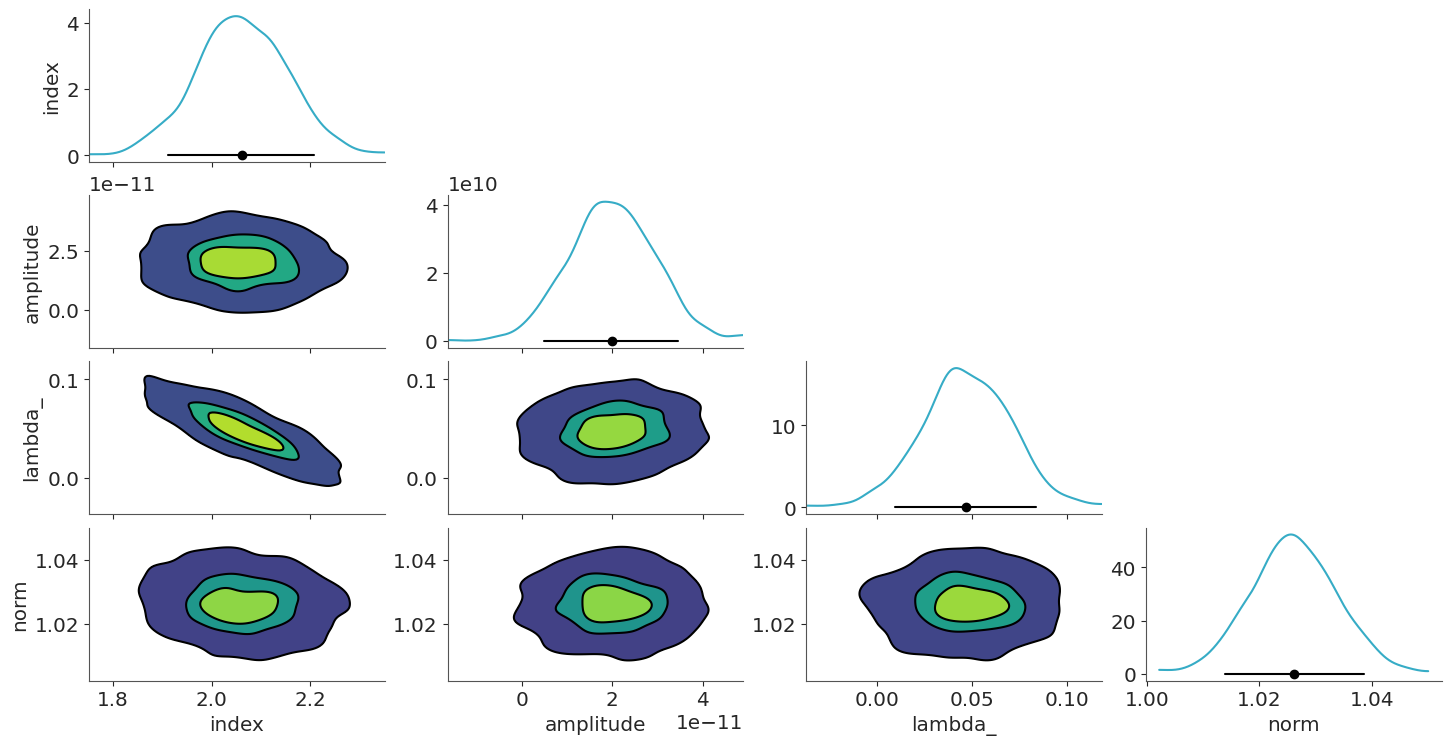

In [34]:

data = sample_parameters_from_covariance(results_stacked.models, n_samples=n_samples)

az.plot_pair(
    data,
    marginal=True,
    marginal_kind="kde",
    visuals={
             "credible_interval":{"color":"k"},"point_estimate":{"color":"k"},
             "contourf": True,
             "contour": {"color":"black"},
             "scatter":False,
    }
)
plt.show()

Here, we see that the statistical uncertainties derived from the covariance matrix do not fully capture the impact of observation-to-observation variations on the fitted parameters. Although the covariance matrix describes the correlations between parameters, such as the background normalisation and the source amplitude, it only reflects the statistical uncertainty around the best-fit solution. In contrast, the jackknife test explores how the fitted parameters vary when different observations are removed, making it sensitive to additional systematic effects and data-selection biases.

In addition, the covariance approach estimates the uncertainty by assuming that the likelihood is approximately Gaussian near the best-fit solution. As a result, the derived uncertainties are symmetric and may not accurately describe the true parameter distribution. In contrast, the jackknife method makes no such assumption and can reveal asymmetric, skewed, or even multi-modal parameter distributions.